# ЛР 3: локальная Qwen3-4B, Q4_K_M

Официальные веса Qwen, CUDA, temperature=0, seed=42, лимит 4096 токенов, режим без рассуждений. Пять pilot исключены. Основной эксперимент: 39 задач и 100 строк классификации в каждом режиме 0/5/20-shot. Системная инструкция, условия, train/test совпадают с YandexGPT. Модель не получает эталоны и тестовые метки.

Run All пересчитывает анализ из сохранённых первых ответов. Генерация и исполнение кода модели здесь не выполняются. Прогнозы и параметры зафиксированы до генераций; результаты Yandex и classical baseline уже были известны. Численные статусы гипотез получаются кодом, итоговые выводы и объяснения причин ошибок формулируют участники согласно заданию.

In [1]:
from pathlib import Path
import sys,json,csv,html
from IPython.display import display,HTML,Image
ROOT=next(p for p in [Path.cwd(),*Path.cwd().parents] if (p/'local_runner.py').exists())
sys.path.insert(0,str(ROOT/'scripts'))
from analyze_local import analyze
summary=analyze()
OUT=ROOT/'analysis/local'
def show_json(name): print(json.dumps(json.loads((OUT/name).read_text(encoding='utf-8')),ensure_ascii=False,indent=2))
def show_csv(name):
    with (OUT/name).open(encoding='utf-8-sig',newline='') as f: rows=list(csv.DictReader(f))
    keys=list(rows[0]);display(HTML('<table><tr>'+''.join('<th>'+html.escape(k)+'</th>' for k in keys)+'</tr>'+''.join('<tr>'+''.join('<td>'+html.escape(str(r[k]))+'</td>' for k in keys)+'</tr>' for r in rows)+'</table>'))
def figure(name): display(Image(filename=str(OUT/'figures'/name)))
show_json('summary.json')

{
  "responses": 344,
  "pilot": 5,
  "main": 39,
  "classification": 300,
  "auto_ABF": {
    "accuracy": 0.375,
    "ci_low": 0.16666666666666666,
    "ci_high": 0.5833333333333334
  },
  "auto_ABF_n": 24,
  "code_pass_at_1": 0.5,
  "code_metrics_match": 2,
  "strict_format_errors": 101,
  "hypotheses_status": {
    "H5": "insufficient_data",
    "H10": "confirm",
    "H12": "insufficient_data"
  },
  "overall_39_accuracy": null,
  "manual_review": {
    "B": {
      "n_required": 8,
      "n_paired_scores": 0,
      "kappa": null,
      "status": "pending"
    },
    "C": {
      "n_required": 7,
      "n_paired_scores": 0,
      "kappa": null,
      "status": "pending"
    },
    "D": {
      "n_required": 8,
      "n_paired_scores": 0,
      "flag_agreement": {
        "leakage": {
          "n": 0,
          "kappa": null,
          "agreement": null
        },
        "test_tuning": {
          "n": 0,
          "kappa": null,
          "agreement": null
        },
        "trai

## Протокол, окружение и ресурсы

Ревизия и SHA256 весов — в docs/local_registration.json. n_ctx=8192. Пустой think-блок задаёт режим без рассуждений через шаблон Qwen3, не изменяя общий system/user. У Yandex режим провайдера по умолчанию, поэтому режимы не идентичны. temperature=0 принят для общего протокола, хотя авторы Qwen обычно рекомендуют негридовый sampling.

API локальной модели не тарифицируется. Электроэнергия и амортизация не измерены, поэтому полная стоимость и рубли за правильный ответ неизвестны. На графике сопоставляется только цена API. Время — генерация, без загрузки весов.

{
  "python": "3.12.14",
  "platform": "Windows-11-10.0.26200-SP0",
  "packages": {
    "numpy": "2.3.5",
    "scipy": "1.16.3",
    "scikit-learn": "1.7.2",
    "matplotlib": "3.10.7",
    "nbformat": "5.10.4",
    "nbclient": "0.10.2",
    "llama-cpp-python": null
  },
  "purpose": "Environment for offline analysis; original generation packages are recorded in package-versions.txt."
}
{
  "cpu": "Intel64 Family 6 Model 151 Stepping 5, GenuineIntel",
  "logical_cpus": 12,
  "ram_total_bytes": 34104377344,
  "sampling_scope": "All/resume invocation; pilot and main before monitoring excluded. VRAM is whole device including desktop, not process allocation.",
  "peak_rss_bytes": 3241472000,
  "peak_device_used_mib": 5458
}
Resource samples: 243


stage,n,api_cost_rub,latency_s,input_tokens,output_tokens,mean_latency_s,mean_total_tokens
pilot,5,0,3.3920204000014564,1685,381,0.6784040800002913,413.2
main,39,0,84.1906422000011,15368,10182,2.1587344153846435,655.1282051282051
zero,100,0,51.70830190000197,43581,6877,0.5170830190000197,504.58
five,100,0,95.2757827000014,88181,13245,0.952757827000014,1014.26
twenty,100,0,103.24512190000314,220281,13585,1.0324512190000315,2338.66


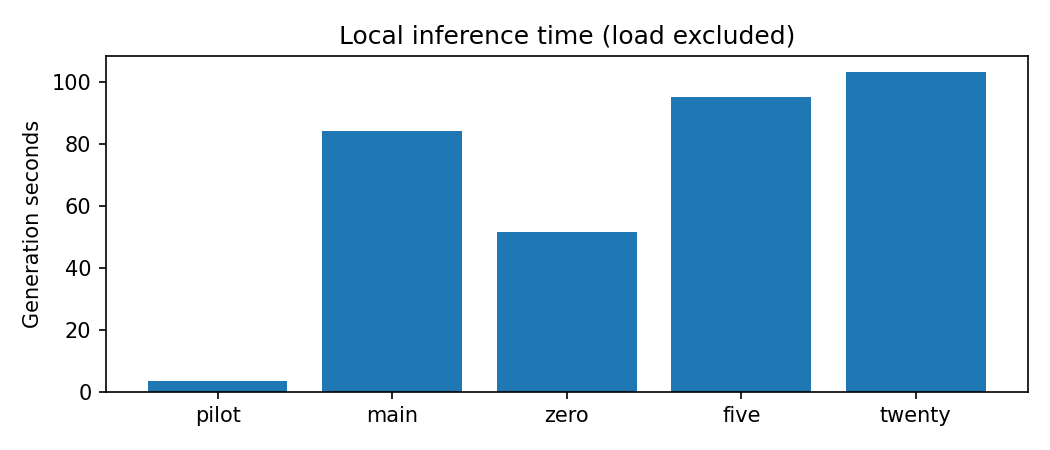

In [2]:
show_json('environment.json')
hardware=json.loads((OUT/'hardware.json').read_text(encoding='utf-8'))
print(json.dumps({k:v for k,v in hardware.items() if k!='samples'},ensure_ascii=False,indent=2))
print('Resource samples:',len(hardware['samples']))
show_csv('costs.csv')
figure('runtime.png')

## A/B/F: автоматическая оценка

24 задачи; допуск чисел из банка, B — только вердикт. Ошибки формата входят в знаменатель как неуспех. Можно снять лишь внешнее Markdown-ограждение с отдельным флагом. Объяснения B и ответы C/D требуют двух независимых проверяющих. Непараметрический bootstrap (1000, seed=42) на восьми задачах даёт грубые интервалы, на 8/8 — вырожденный интервал, не гарантию качества на новых задачах.

type,n,accuracy,ci_low,ci_high
A,8,0.0,0.0,0.0
B,8,0.75,0.375,1.0
F,8,0.375,0.12187500000000018,0.75


task_id,type,parsed,answer,correct,confidence,format_error,cost_rub
A01,A,True,0.02,False,100,,0
A02,A,True,0.16666666666666666,False,75,,0
A03,A,True,0.311,False,90,,0
A04,A,True,1.25,False,100,,0
A05,A,True,0.880797,False,100,,0
A06,A,True,0,False,80,,0
A07,A,False,,False,,response_not_completed,0
A08,A,True,0.7,False,100,,0
B01,B,True,False,True,75,,0
B02,B,True,False,True,70,,0


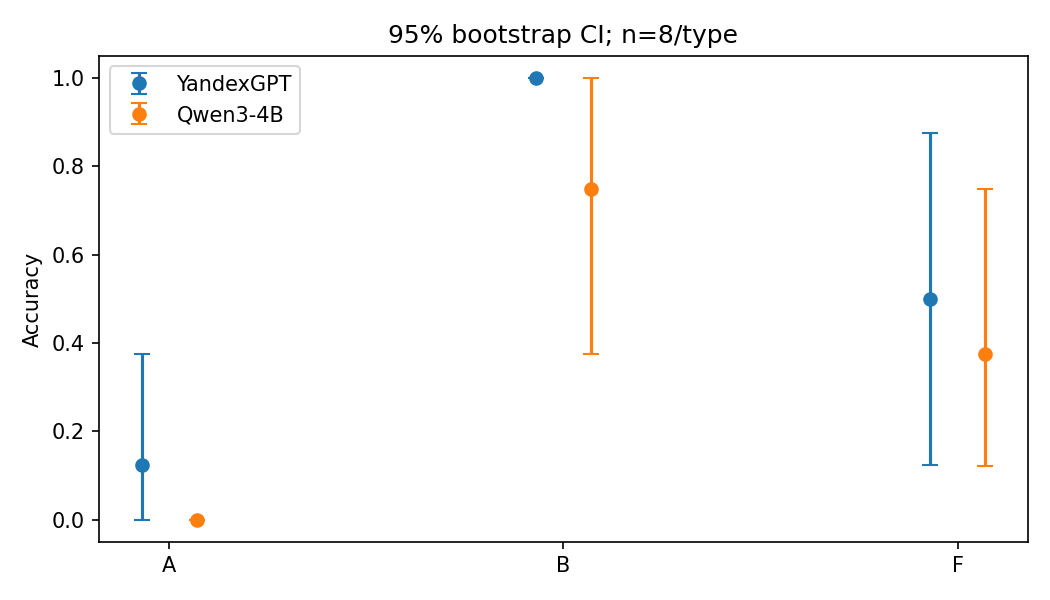

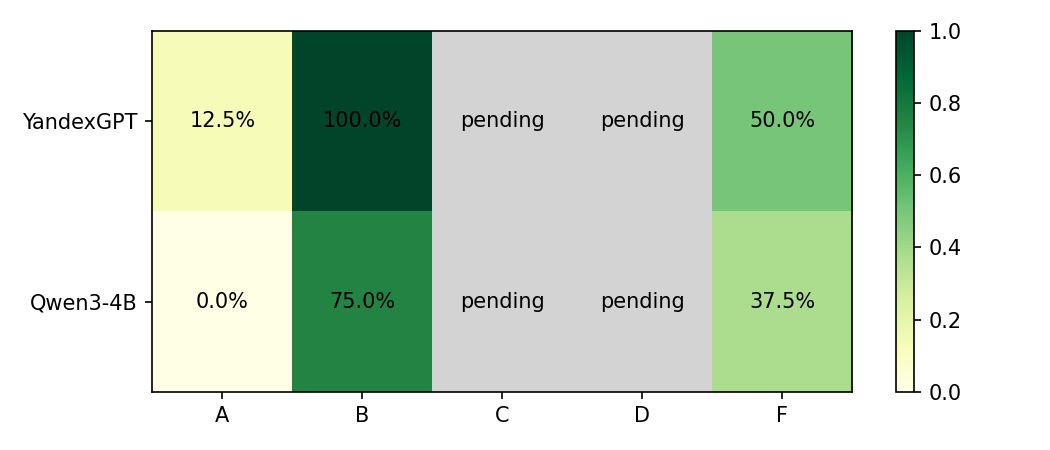

In [3]:
show_csv('type_metrics.csv')
show_csv('automatic_scores.csv')
figure('accuracy_ci.png')
figure('heatmap.png')

## H5: отставание по A относительно B

Сравнение заранее выбрано: YandexGPT Pro 5.1 против Qwen3 4B. Статистика (Yandex_A−Qwen_A)−(Yandex_B−Qwen_B). Парный bootstrap внутри A/B, 95% CI; нижняя граница >0 подтверждает, верхняя ≤0 опровергает, иначе insufficient_data. Размер модели смешан с обучением, квантованием и режимом генерации, поэтому это не причинный эксперимент размера.

{
  "statistic_gap_A_minus_gap_B": -0.125,
  "ci_low": -0.5,
  "ci_high": 0.25,
  "decision": "insufficient_data",
  "n_A": 8,
  "n_B": 8,
  "seed": 42,
  "bootstrap_iterations": 1000
}


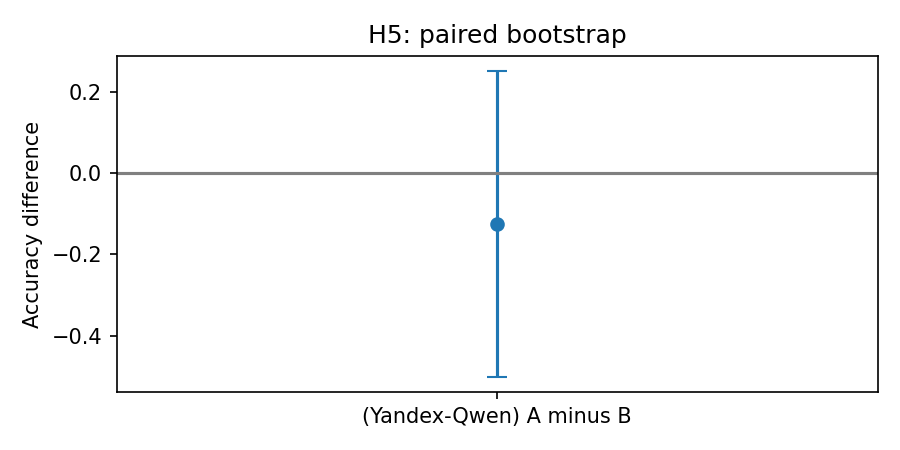

{
  "n": 24,
  "yandex_only_correct": 4,
  "local_only_correct": 0,
  "exact_two_sided_p": 0.125,
  "scope": "One available LLM pair on A+B+F; no four-model family yet; exploratory."
}


In [4]:
hypotheses=json.loads((OUT/'hypotheses.json').read_text(encoding='utf-8'))
print(json.dumps(hypotheses['H5'],ensure_ascii=False,indent=2))
figure('h5_gap.png')
show_json('paired_comparison.json')

## H10: уверенность

Выбраны A+B+F. Средняя confidence и accuracy считаются на разбираемых ответах; coverage и полный знаменатель показаны отдельно. Кластерный bootstrap сохраняет связанные варианты F. Signed gap задаёт направление; ECE с пятью bins — размер расхождения без направления. Три гипотезы исследовательские, интервалы не скорректированы как единое семейство.

{
  "n_total": 24,
  "n_valid": 22,
  "coverage": 0.9166666666666666,
  "mean_confidence": 0.8636363636363636,
  "accuracy_on_valid": 0.4090909090909091,
  "full_denominator_accuracy": 0.375,
  "gap": 0.45454545454545453,
  "ci_low": 0.21422619047619043,
  "ci_high": 0.6650795454545454,
  "ece": 0.45454545454545464,
  "decision": "confirm",
  "bins": [
    {
      "bin_low": 0.0,
      "bin_high": 0.2,
      "n": 0,
      "mean_confidence": null,
      "accuracy": null
    },
    {
      "bin_low": 0.2,
      "bin_high": 0.4,
      "n": 0,
      "mean_confidence": null,
      "accuracy": null
    },
    {
      "bin_low": 0.4,
      "bin_high": 0.6,
      "n": 0,
      "mean_confidence": null,
      "accuracy": null
    },
    {
      "bin_low": 0.6,
      "bin_high": 0.8,
      "n": 6,
      "mean_confidence": 0.7333333333333334,
      "accuracy": 0.6666666666666666
    },
    {
      "bin_low": 0.8,
      "bin_high": 1.0,
      "n": 16,
      "mean_confidence": 0.9125000000000001,
  

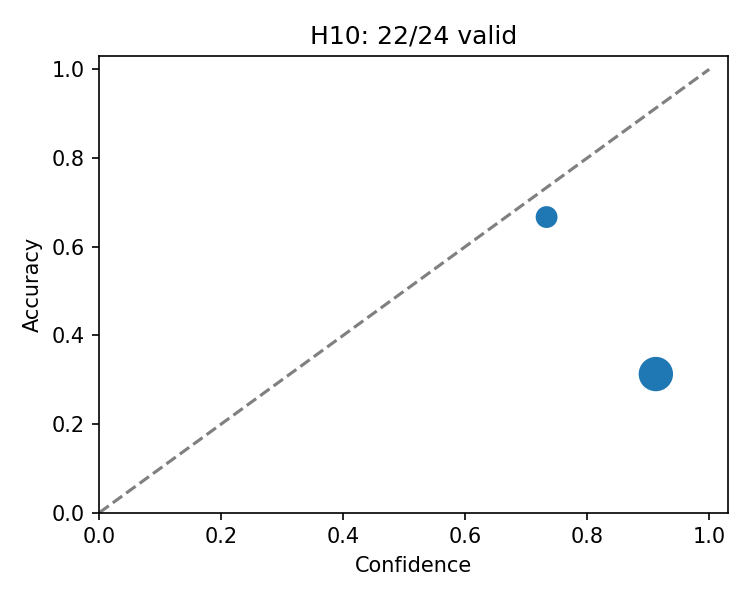

In [5]:
print(json.dumps(hypotheses['H10'],ensure_ascii=False,indent=2))
figure('reliability.png')

## E и H12: few-shot классификация

100 общих строк, шесть признаков; 1=malignant, 0=benign. Это обратная исходной sklearn кодировка (D08 использует исходную). Отказ/невалидный формат = -1 и ошибка для истинного класса. Train5 вложен в train20. У baseline нет zero-shot режима. Основная метрика F1 класса 1, дополнительная balanced accuracy; интервалы условны на один фиксированный набор демонстраций.

Для H12 delta=F1_Qwen−F1_LR. При 5-shot нижняя односторонняя 95% граница должна быть >−0.05; при 20-shot верхняя <0. Парный bootstrap использует одни и те же тестовые строки. Критерии взяты из регистрации Yandex до ответов Qwen.

model,shots,f1_minority,balanced_accuracy,accuracy,coverage,abstentions,explicit_refusals,other_unscored
Qwen3-4B,0,0.0,0.015873015873015872,0.02,0.04,96,96,0
Qwen3-4B,5,0.8505747126436781,0.8968253968253967,0.87,1.0,0,0,0
Qwen3-4B,20,0.9041095890410958,0.9221364221364221,0.93,1.0,0,0,0
LogisticRegression,5,0.8043478260869565,0.8571428571428572,0.82,1.0,0,0,0
LogisticRegression,20,0.9117647058823529,0.9189189189189189,0.94,1.0,0,0,0
GaussianNB,5,0.8043478260869565,0.8571428571428572,0.82,1.0,0,0,0
GaussianNB,20,0.8181818181818182,0.848991848991849,0.88,1.0,0,0,0
constant_majority,0,0.0,0.5,0.63,1.0,0,0,0


[
  {
    "model": "Qwen3-4B",
    "shots": 0,
    "f1_minority": 0.0,
    "balanced_accuracy": 0.015873015873015872,
    "accuracy": 0.02,
    "coverage": 0.04,
    "abstentions": 96,
    "ci": {
      "f1_minority": [
        0.0,
        0.0
      ],
      "balanced_accuracy": [
        0.0,
        0.04033492429229755
      ],
      "accuracy": [
        0.0,
        0.05
      ]
    },
    "explicit_refusals": 96,
    "other_unscored": 0
  },
  {
    "model": "Qwen3-4B",
    "shots": 5,
    "f1_minority": 0.8505747126436781,
    "balanced_accuracy": 0.8968253968253967,
    "accuracy": 0.87,
    "coverage": 1.0,
    "abstentions": 0,
    "ci": {
      "f1_minority": [
        0.7631265664160402,
        0.925
      ],
      "balanced_accuracy": [
        0.8467741935483871,
        0.9470242681047766
      ],
      "accuracy": [
        0.8,
        0.9302499999999998
      ]
    },
    "explicit_refusals": 0,
    "other_unscored": 0
  },
  {
    "model": "Qwen3-4B",
    "shots": 2

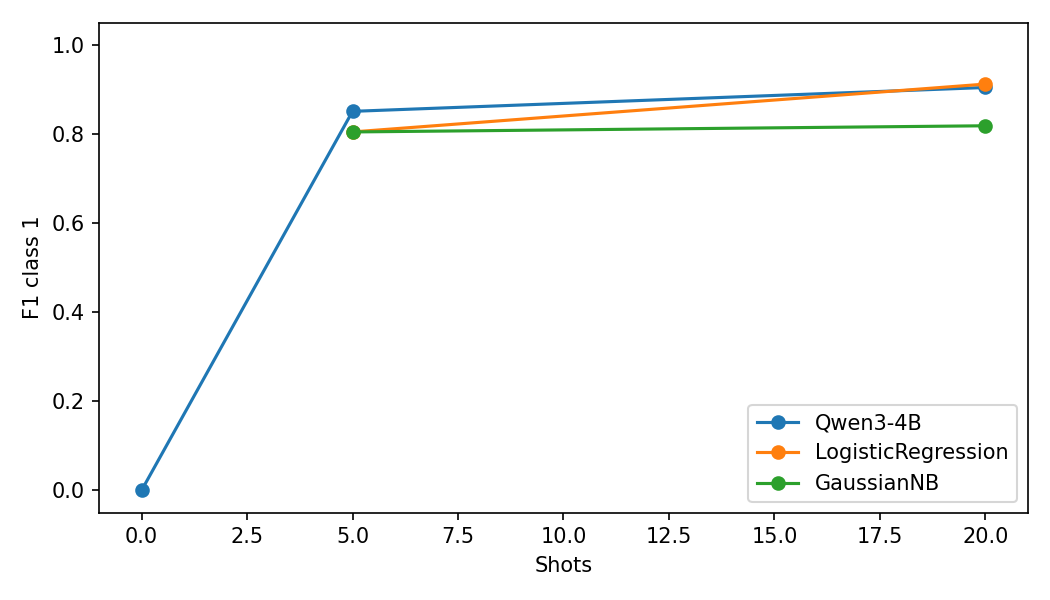

{
  "decision": "insufficient_data",
  "comparisons": [
    {
      "shots": 5,
      "delta_f1_llm_minus_lr": 0.04622688655672158,
      "one_sided_95_lower": -0.01032617171857687,
      "one_sided_95_upper": 0.10910561929979397,
      "decision": "confirm"
    },
    {
      "shots": 20,
      "delta_f1_llm_minus_lr": -0.007655116841257081,
      "one_sided_95_lower": -0.0683356315046456,
      "one_sided_95_upper": 0.058142321346770436,
      "decision": "insufficient_data"
    }
  ]
}


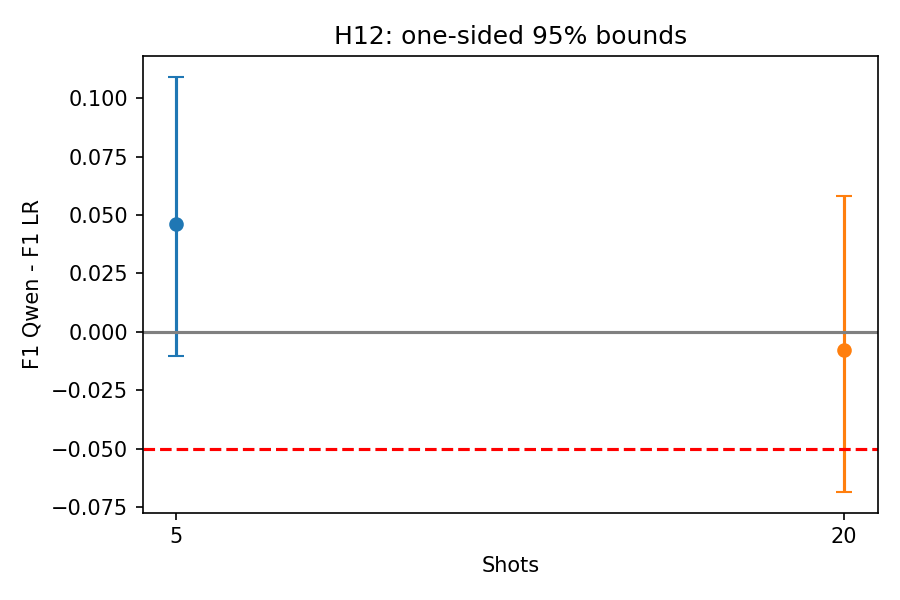

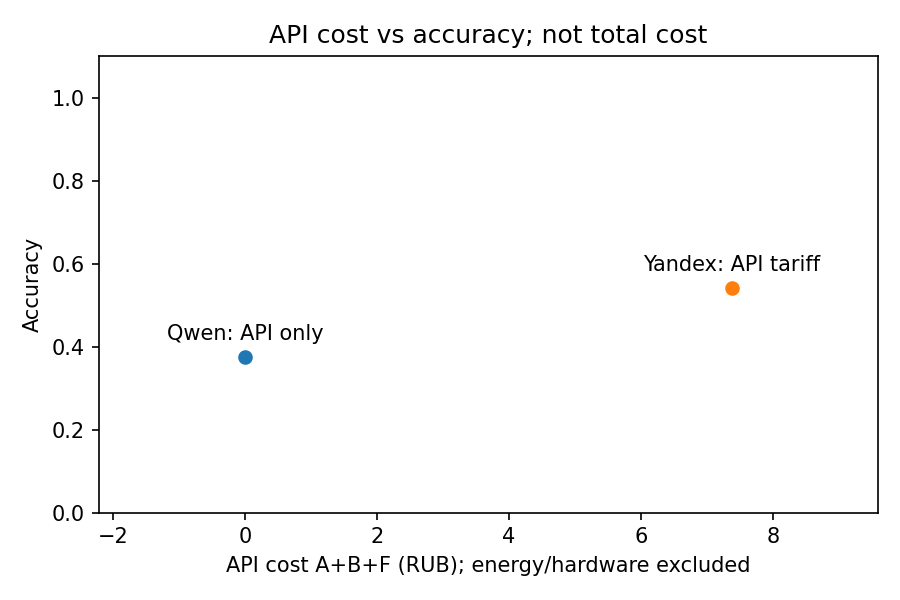

In [6]:
show_csv('classification_metrics.csv')
show_json('classification_metrics.json')
figure('classification_f1.png')
print(json.dumps(hypotheses['H12'],ensure_ascii=False,indent=2))
figure('h12_delta.png')
figure('cost_accuracy.png')

## C: выбор метода — ответы модели

Для каждой задачи показаны условие, исходный ответ, обоснование и уверенность модели. Ответы могут содержать ошибки и отказы: здесь они отображаются без исправлений. Если JSON корректен, но тип answer не соответствует протоколу, ответ всё равно виден с пометкой ошибки формата; его оценка не меняется.

In [7]:
records=[json.loads(s) for s in (ROOT/'results/models/local/qwen3-4b-q4-v1/responses.jsonl').read_text(encoding='utf-8').splitlines()]
tasks={r['id']:r for r in [json.loads(s) for s in (ROOT/'data/tasks.jsonl').read_text(encoding='utf-8').splitlines()]}
executions={r['task_id']:r for r in json.loads((OUT/'code_execution.json').read_text(encoding='utf-8'))}

def pre(value):
    if not isinstance(value,str):
        value=json.dumps(value,ensure_ascii=False,indent=2)
    return '<pre style="white-space:pre-wrap">'+html.escape(value)+'</pre>'

def show_answers(prefix):
    for r in sorted([r for r in records if r['stage']=='main' and r['task_id'].startswith(prefix)],key=lambda r:r['task_id']):
        text='\n'.join(part.get('text','') for block in r['raw_response'].get('output',[]) for part in (block.get('content') or []) if part.get('type')=='output_text')
        obj=r.get('parsed')
        if obj is None:
            # Decode valid JSON for display only. Scoring and original records stay unchanged.
            try:
                candidate=json.loads(text)
                obj=candidate if isinstance(candidate,dict) else None
            except ValueError:
                obj=None
        content='<h3>'+r['task_id']+'</h3><b>Условие</b>'+pre(tasks[r['task_id']]['text_ru'])
        if r.get('error'):
            content+='<p><b>Ошибка формата:</b> '+html.escape(r['error'])+'</p>'
        if obj is not None and 'answer' in obj:
            label='Код модели' if prefix=='D' and isinstance(obj['answer'],str) else 'Ответ модели'
            content+='<b>'+label+'</b>'+pre(obj['answer'])
            if prefix=='D' and not isinstance(obj['answer'],str):
                content+='<p>Модель не предоставила код: поле answer имеет другой тип.</p>'
            if 'explanation' in obj:
                content+='<b>Обоснование модели</b>'+pre(obj['explanation'])
            if 'confidence' in obj:
                content+='<p><b>Уверенность модели:</b> '+html.escape(str(obj['confidence']))+'%</p>'
        else:
            content+='<b>Исходный ответ модели (JSON не удалось разобрать)</b>'+pre(text)
        display(HTML(content))
        if prefix=='D':
            result=executions[r['task_id']]
            display(HTML('<b>Сохранённый результат проверки</b>'+pre({k:result[k] for k in ['status','exit_code','pass_at_1','output_is_json','metrics_match_reference']})))
            for suffix,label in [('stdout.txt','Вывод программы (stdout)'),('stderr.txt','Ошибки программы (stderr)')]:
                path=OUT/'code_execution'/(r['task_id']+'.'+suffix)
                if path.exists():
                    value=path.read_text(encoding='utf-8')
                    display(HTML('<b>'+label+'</b>'+(pre(value) if value else '<p>Пустой вывод.</p>')))

show_answers('C')

## D: код модели и результаты его запуска

Ниже код отображается обычным многострочным текстом. Показаны сохранённые stdout/stderr, факт запуска и совпадение метрик с эталоном. Run All не выполняет код модели повторно. Если модель прислала число вместо кода или некорректный JSON, показан именно этот исходный ответ. Предварительная техническая проверка не заменяет двух независимых оценок методологии.

In [8]:
show_answers('D')
show_csv('code_metrics.csv')
show_json('code_execution.json')

task_id,source_sha256,exit_code,pass_at_1,output_is_json,metrics_match_reference,status,format_error,stderr_original_sha256,methodology_review
D01,9827482c6a1abab33d4cb8633bdfff1634649d2413016a589df4a2bec441361e,1,False,False,False,executed_first_answer,,089b3f694df51e082ef90247b6ade44a3d13c4d9a4df5c8e1f08d146200c4b6a,pending_two_independent_reviewers
D02,da8ba0bed21d0fcc863a07c8f9a46cd163ab07ecaec47c270991956904a81665,0,True,True,True,executed_first_answer,,e3b0c44298fc1c149afbf4c8996fb92427ae41e4649b934ca495991b7852b855,pending_two_independent_reviewers
D03,182d104fc2e24c7f1ff7c2a44a92422c79b6e50850f9b2a9b5a801111ca77920,0,True,False,False,executed_first_answer,,e3b0c44298fc1c149afbf4c8996fb92427ae41e4649b934ca495991b7852b855,pending_two_independent_reviewers
D04,,,False,False,False,not_executable_response_format,invalid_json,,pending_two_independent_reviewers
D05,,,False,False,False,not_executable_response_format,invalid_answer_type,,pending_two_independent_reviewers
D06,59604d552446a8c97fe767a82d36ac7ff63f32046ebd852732fc4606ac5cd10b,1,False,False,False,executed_first_answer,,ae6116d48672dd192a05329ec1585cff18b339307d49d891937da202f6d954d1,pending_two_independent_reviewers
D07,0aa00b17bea3a68bdac3e47f9900571a51bd896cd1249116d79ea991077c408e,0,True,False,False,executed_first_answer,,e3b0c44298fc1c149afbf4c8996fb92427ae41e4649b934ca495991b7852b855,pending_two_independent_reviewers
D08,781495d3031b976b7879d456897c0fff24db8201150442e72b854eaeb767a650,0,True,True,True,executed_first_answer,,e3b0c44298fc1c149afbf4c8996fb92427ae41e4649b934ca495991b7852b855,pending_two_independent_reviewers


[
  {
    "task_id": "D01",
    "source_sha256": "9827482c6a1abab33d4cb8633bdfff1634649d2413016a589df4a2bec441361e",
    "exit_code": 1,
    "pass_at_1": false,
    "output_is_json": false,
    "metrics_match_reference": false,
    "metrics": null,
    "status": "executed_first_answer",
    "format_error": null,
    "stderr": "  File \"<project>/D01.py\", line 13\n    x_train, x_test, y_train, y y_test = train_test_split(x, y, test_size=0.25, random_state=42, stratify=y)\n                                ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^\nSyntaxError: invalid syntax. Maybe you meant '==' or ':=' instead of '='?\n",
    "stderr_original_sha256": "089b3f694df51e082ef90247b6ade44a3d13c4d9a4df5c8e1f08d146200c4b6a",
    "methodology_review": "pending_two_independent_reviewers"
  },
  {
    "task_id": "D02",
    "source_sha256": "da8ba0bed21d0fcc863a07c8f9a46cd163ab07ecaec47c270991956904a81665",
    "exit_code": 0,
    "pass_at_1": true,
    "output_

## Независимая проверка и разбор ошибок

Пакет analysis/local/review/ содержит рубрики и две пустые формы. Для слепой проверки организатор перемешивает ответы разных моделей. Два участника независимо выставляют оценки B/C и флаги D, затем сравнивают их и считают kappa; пропуски не заменяются нулями. student_analysis в примерах оставлено участникам. Если автоматических ошибок меньше пяти, дополнительные случаи следует выбрать из C/D после ручной проверки, не выдумывать ошибки.

Финальный текст отчёта, практические рекомендации и пятиминутный доклад заполняет команда. Ограничения для обсуждения: восемь задач на тип, публичный датасет, единственный few-shot набор, зависимость F-пар, различие режимов и квантование. Общая accuracy по 39 задачам до ручной проверки не заявляется.

In [9]:
show_json('error_examples.json')
show_json('review_status.json')
show_json('provenance.json')

[
  {
    "task_id": "A01",
    "prompt": "Дефект имеют 2% деталей. Датчик срабатывает на 96% дефектных и на 4% исправных деталей. Найдите вероятность дефекта при срабатывании датчика. Ответ дайте долей от 0 до 1.",
    "raw_response": "{\"answer\": 0.02, \"explanation\": \"Вероятность дефекта при срабатывании датчика равна вероятности того, что деталь дефектна, что составляет 2%.\", \"confidence\": 100}",
    "reference": {
      "answer": 0.3287671232876712,
      "solution_ru": "P(D|+) = 0.02*0.96 / (0.02*0.96 + 0.98*0.04) = 24/73."
    },
    "student_analysis": ""
  },
  {
    "task_id": "A02",
    "prompt": "В узле дерева 36 объектов класса 0 и 24 класса 1. После разбиения в левом узле (30; 6), в правом (6; 18). Найдите уменьшение impurity Джини: impurity родителя минус взвешенная impurity детей.",
    "raw_response": "{\"answer\": 0.16666666666666666, \"explanation\": \"Импурити Джини для узла родителя: 1 - (36/60)^2 - (24/60)^2 = 1 - 0.36 - 0.16 = 0.48. Взвешенная импурити дете